# Plotting Notebook

## 1. Setup notebook

In [7]:
import sys
print(sys.executable)
import socket
print(socket.gethostname())
import os
os.chdir("/home/shanson/foggie-dynamics")
print(os.getcwd())

/home/brs/tmox-2024/miniconda3/envs/yt/bin/python
fcfs5
/home/shanson/foggie-dynamics


In [8]:
import yt # type: ignore
yt.set_log_level("warning")
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm

plt.style.use('/home/shanson/foggie-dynamics/config/paper.mplstyle')

%matplotlib inline

import src
from src import (
    FittingResult,
    ProjectPaths,
    DensityProfile,
    ModelRegistry,
    load_hdf5,
    load_config,
    get_plot_config,
    apply_axis_style,
    get_component_colors,
    plot_2d_model_comparison,
    plot_combined_components,
    plot_component_mass_evolution,
    plot_corner,
    plot_data_mass_evolution,
    plot_fitted_mass_evolution,
    plot_halo_shape_evolution,
    plot_profiles,
    plot_reddish_2022_figure,
    plot_results,
    plot_shape_analysis,
)
    
PATHS = ProjectPaths.create(
    code_root=Path("/home/shanson/foggie-dynamics"),
    data_root=Path("/cephfs/shanson/FOGGIE")
)
RESULTS_DIR = PATHS.results
DATA_DIR = PATHS.data
PLOTS_DIR = PATHS.plots

config = load_config(str(PATHS.config_file('fitting_config_r200.yaml')))
experiment = 'r200_scaling'

halos = ["halo_002392", "halo_002878", "halo_004123", "halo_005016", "halo_005036", "halo_008508"]
names = ['Hurricane', 'Cyclone', 'Blizzard', 'Squall', 'Maelstrom', 'Tempest']


## Select halo & redshift

Edit the cells below to choose which halo/snapshot to visualise. Run the cell to derive all paths.

In [9]:
# --- Edit these ---
HALO      = halos[-1]   # e.g. halos[0] = "halo_002392" (Hurricane)
NAME      = names[-1]   # must match HALO index
REDSHIFT  = 0.0         # pick from printed list below
COMP      = "dm"        # star | gas | dm
REGION    = "halo"      # bulge | disk | halo
# ------------------

halo_ev_data = load_hdf5(PATHS.results / experiment / HALO / "evolution_time_series.h5")
redshifts = halo_ev_data['time']['redshifts']
print(f"Available redshifts for {HALO}/{NAME}:\n{redshifts}")

data_path    = PATHS.snapshot_data(HALO, REDSHIFT, experiment=experiment)
results_path = PATHS.snapshot_results(HALO, REDSHIFT, experiment=experiment)
plot_path    = PATHS.snapshot_plots(HALO, REDSHIFT, experiment=experiment)
print(f"\nUsing z={REDSHIFT:.3f}  →  {data_path}")

Available redshifts for halo_008508/Tempest:
[5.99999769 4.99999904 3.99999897 3.49999971 2.99999975 2.74999943
 2.49999962 2.24999976 1.99999969 1.74999993 1.49999993 1.39999989
 1.2999999  1.19999984 1.09999991 0.99999996 0.89999999 0.79999998
 0.69999999 0.59999997 0.49999999 0.44999996 0.39999997 0.34999998
 0.29999997 0.24999999 0.19999999 0.14999996 0.09999997 0.04999999
 0.        ]

Using z=0.000  →  /ceph/cephfs/shanson/FOGGIE/data/r200_scaling/halo_008508/z_0.000


## 1. Density profiles

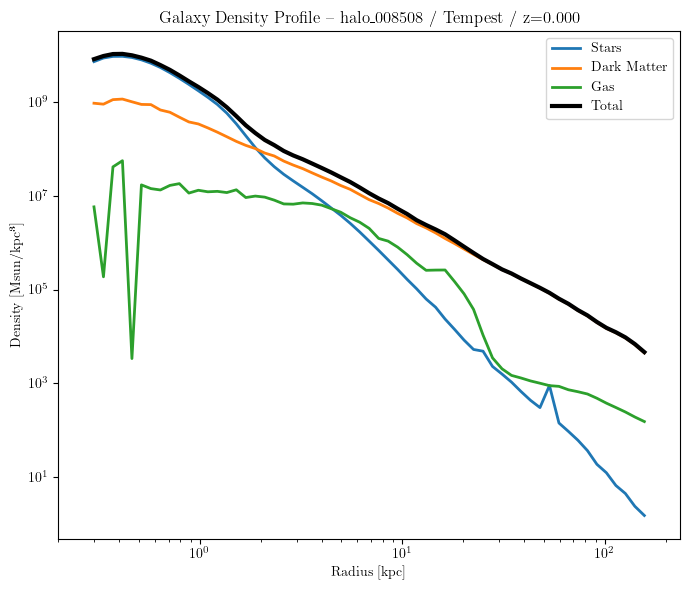

In [29]:
plot_profiles(HALO, NAME, REDSHIFT, PATHS, config, save_fig=False, experiment=experiment, show_fig=True)
plt.show()

## 2. Shape analysis

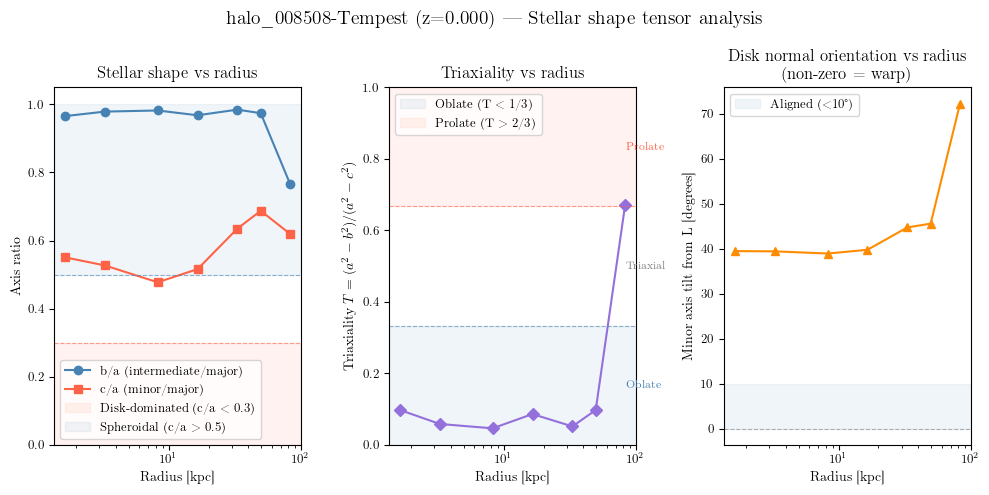

In [13]:
metadata = load_hdf5(data_path / "metadata.h5")

if "shape_tensors" in metadata:
    plot_shape_analysis(HALO, NAME, REDSHIFT, config, PATHS, save_fig=True, experiment=experiment, show_fig=True, metadata=metadata)
    plt.show()
else:
    print("No shape tensor data at this snapshot")

## 3. Fitting results

Set `COMP` and `REGION` in the selection cell above, then run this cell to load the profile and results.

In [4]:
profile_file = data_path / f"3d_profile_{COMP}.h5"
comp_profile = DensityProfile.from_hdf5(str(profile_file), COMP, False)

comp_reg_results = load_hdf5(str(results_path / f"{COMP}_{REGION}_results.h5"))
models     = [k for k in comp_reg_results.keys() if k != 'best_model']
evaluators = {m: ModelRegistry.get_evaluator(m) for m in models}
best_model = str(comp_reg_results['best_model'])

if REGION == "bulge":
    data_range = {0: (0.8, 5)}
elif REGION == "halo":
    data_range = {0: (min(comp_profile.r_1d), max(comp_profile.r_1d))} if COMP == "dm" else {0: (15, max(comp_profile.r_1d))}
else:
    data_range = None

print(f"Best model for {COMP}/{REGION}: {best_model}")

yt : [WARNING  ] 2026-03-21 14:54:04,605 Geometric data selection not available for this dataset type.


Best model for dm/halo: NFW


### 3a. 1D fit (bulge / halo)

  rho0 = 4.088e+07
  rs = 5.570e+00
  Model eval range: [2.347e+03, 8.667e+08]


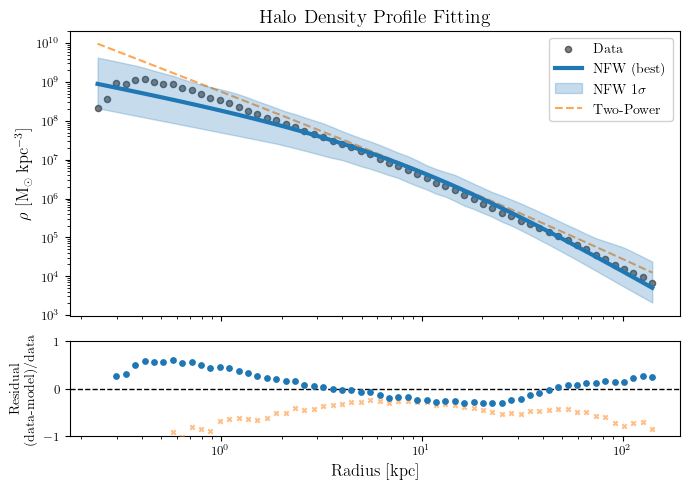

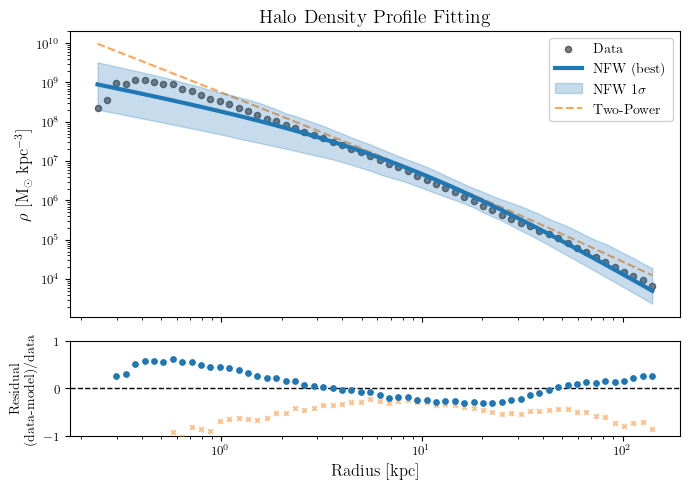

In [7]:
plot_results(
    coords=(comp_profile.r_1d,),
    data=comp_profile.rho_1d,
    model_summaries=comp_reg_results,
    data_range=data_range,
    coord_label="Radius [kpc]",
    best_model_name=best_model,
    component_name=REGION,
    save_path=None,
    model_evaluators=evaluators,
    config=config
)
plt.show()

### 3b. 2D disk fit

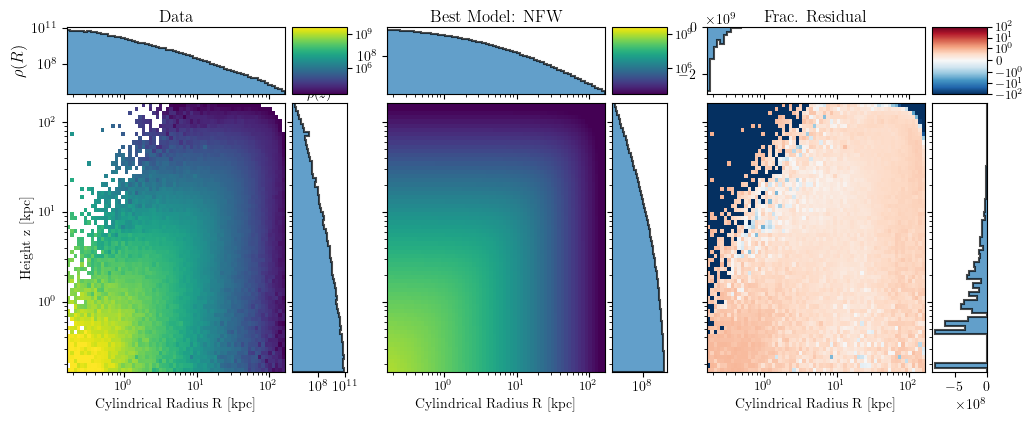

In [22]:
plot_2d_model_comparison(
    R_bins=comp_profile.R_bins,
    z_bins=comp_profile.z_bins,
    rho_data=comp_profile.rho_2d,
    model_evaluator=evaluators[best_model],
    model_summary=comp_reg_results[best_model],
    model_name=best_model,
    config=config,
    savefig=None,
)
plt.show()

### 3c. Corner plot

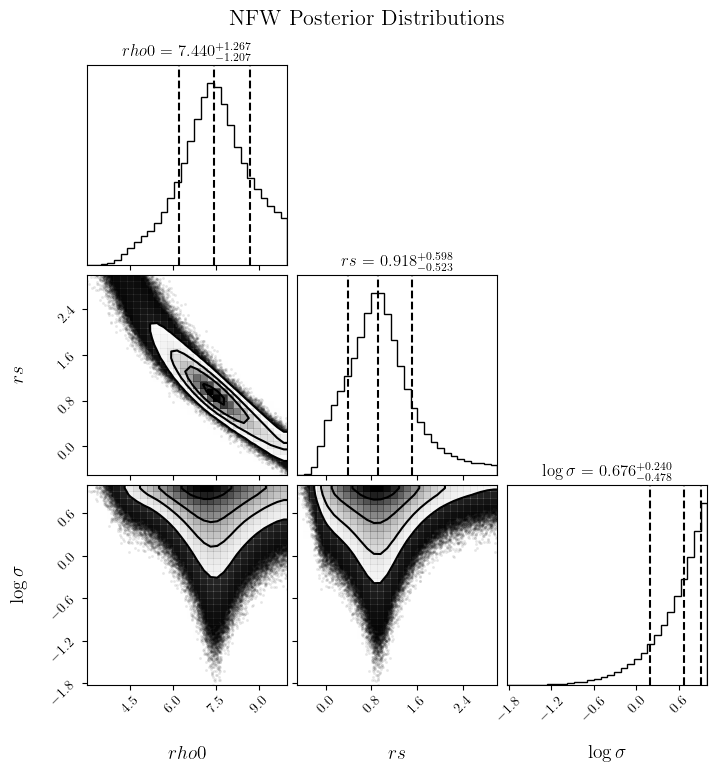

In [23]:
plot_corner(
    model_name=best_model,
    summary=comp_reg_results[best_model],
    save_path=None,
)
plt.show()

### 3d. Combined component decomposition

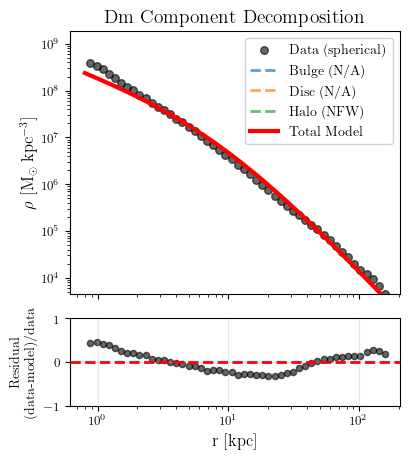

In [24]:
regions = ["bulge", "disk", "halo"]
comp_results = {
    r: FittingResult.from_hdf5(results_path / f"{COMP}_{r}_results.h5")
    for r in regions
    if (results_path / f"{COMP}_{r}_results.h5").exists()
}
plot_combined_components(
    results=comp_results,
    profile=comp_profile,
    component_type=COMP,
    r_range=(0.8, max(comp_profile.r_1d)),
    save_path=None,
)
plt.show()

## 4. Mass evolution

Plots fitted and data-based mass profiles over all snapshots for a given component.

In [25]:
for comp in ['star', 'gas', 'dm', 'baryon', 'total']:
    try:
        plot_fitted_mass_evolution(HALO, NAME, comp, config, PATHS, save_fig=False, experiment=experiment)
        plt.show()
    except Exception as e:
        print(f"fitted mass evolution [{comp}]: {e}")
    try:
        plot_data_mass_evolution(HALO, NAME, comp, config, PATHS, save_fig=False, experiment=experiment)
        plt.show()
    except Exception as e:
        print(f"data mass evolution [{comp}]: {e}")

## 5. Component mass ratios

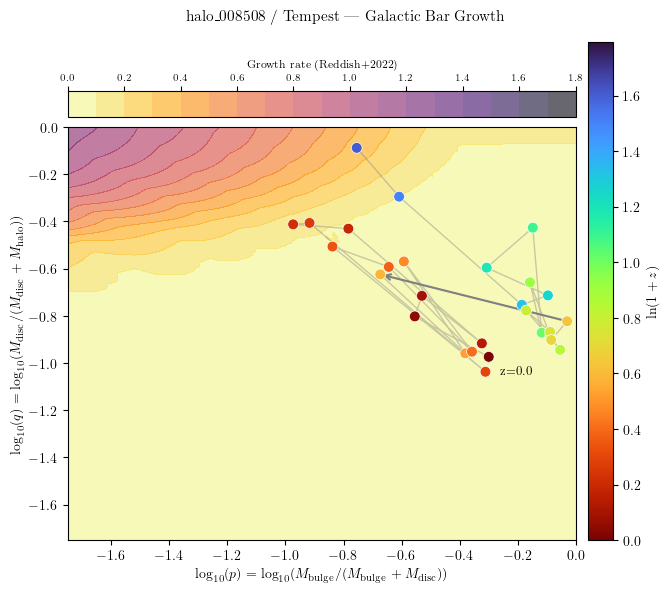

In [26]:
plot_component_mass_evolution(HALO, NAME, config, PATHS, save_fig=False, experiment=experiment)
plt.show()

plot_reddish_2022_figure(
    HALO, NAME, config, PATHS, save_fig=False, experiment=experiment,
    background_data_file="/home/shanson/foggie-dynamics/datasets/Dump_Growth_Rate_Rotation_eps0_1_test_z1dot3 1.hf5",
    show_fig=True
)
plt.show()

## 6. Halo shape evolution

/home/shanson/foggie-dynamics/src/plotting.py:2397: RuntimeWarning: divide by zero encountered in log
  return np.log(1 + z)


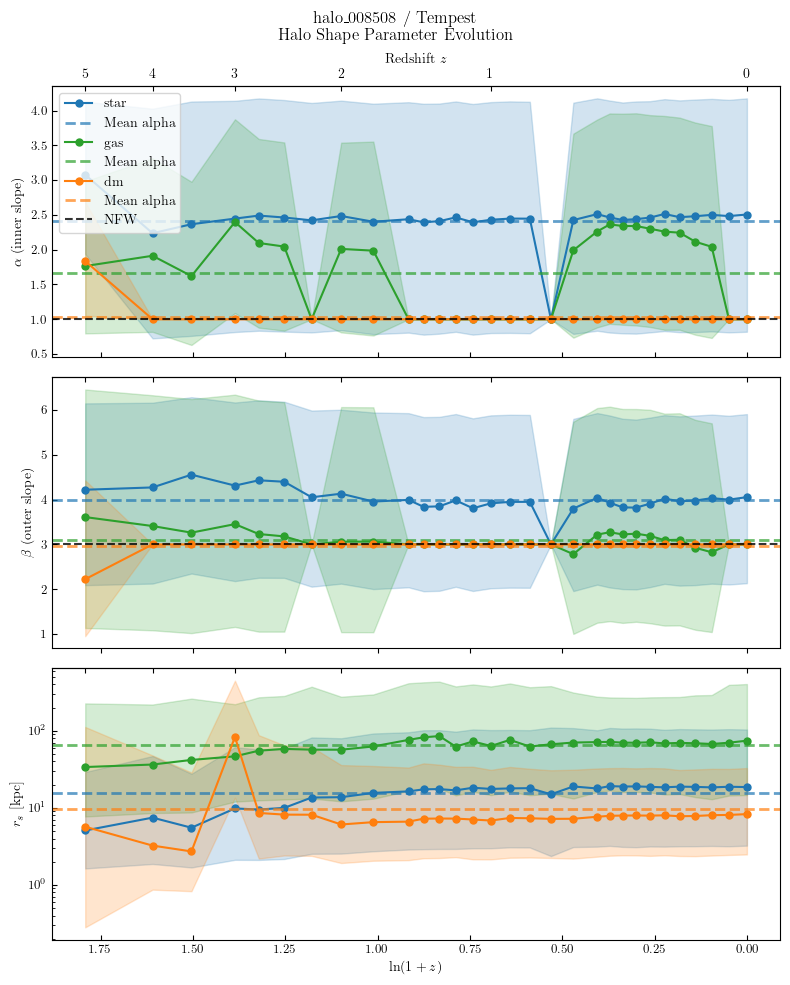

In [27]:
plot_halo_shape_evolution(
    halo=HALO,
    name=NAME,
    config=config,
    PATHS=PATHS,
    save_fig=False,
    experiment=experiment,
    show_fig=True
)
plt.show()

## Additional Plots

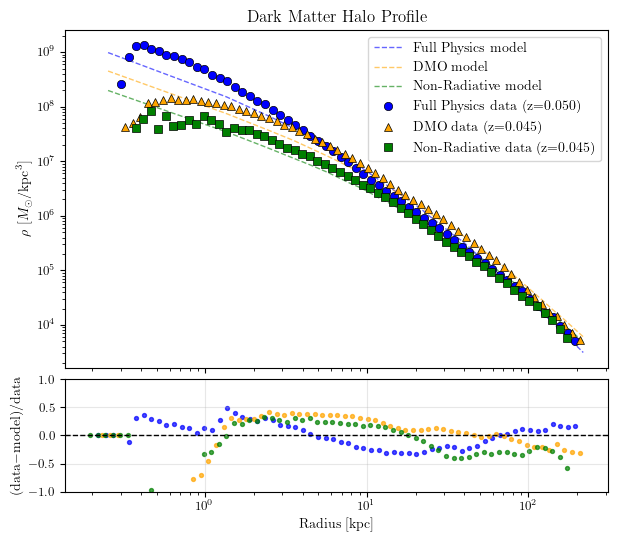

In [28]:
from src import DensityProfile, FittingResult, ModelRegistry, save_figure, get_plot_config, apply_axis_style
import numpy as np

config = load_config(str(PATHS.config_file('fitting_config_r200.yaml')))
plt_cfg = get_plot_config(config, 'profile_1d')

POISSON_ERR = 0.12

full_data_path = PATHS.snapshot_data('halo_005036', 0.05, experiment='r200_scaling')
dmo_data_path = PATHS.snapshot_data('halo_005036', 0.045, experiment='dm_only_r200')
gas_data_path = PATHS.snapshot_data('halo_005036', 0.045, experiment='gas_sim')
full_data = DensityProfile.from_hdf5(full_data_path/"3d_profile_dm.h5", 'dm')
full_meta = load_hdf5(full_data_path/"metadata.h5")
dmo_data = DensityProfile.from_hdf5(dmo_data_path/"3d_profile_dm.h5", 'dm')
dmo_meta = load_hdf5(dmo_data_path/"metadata.h5")
gas_data = DensityProfile.from_hdf5(gas_data_path/"3d_profile_dm.h5", 'dm')
gas_meta = load_hdf5(gas_data_path/"metadata.h5")


z_full = full_meta.get('redshift', 1.2)
z_dmo = dmo_meta.get('redshift', 1.203)
z_gas = gas_meta.get('redshift', 1.203)

full_r200 = full_meta.get('R200_kpc', 200)
dmo_r200 = dmo_meta.get('R200_kpc', 200)
gas_r200 = gas_meta.get('R200_kpc', 200)

# R200s: full = 114.93, dmo = 125.97, gas = 98.61

full_results = FittingResult.from_hdf5(
    PATHS.snapshot_results('halo_005036', 0.05, 'r200_scaling')/"dm_halo_results.h5"
)
dmo_results = FittingResult.from_hdf5(
    PATHS.snapshot_results('halo_005036', 0.045, 'dm_only_r200')/"dm_halo_results.h5"
)
gas_results = FittingResult.from_hdf5(
    PATHS.snapshot_results('halo_005036', 0.045, 'gas_sim')/"dm_halo_results.h5"
)

r_min = 0.25
r_max = dmo_r200
r = np.linspace(r_min, r_max, 200)

draws = {'full': [], 'dmo': [], 'gas': []}
for type, results in zip(['full', 'dmo', 'gas'], [full_results, dmo_results, gas_results]):
    model = results.best_model
    summary = results.summary
    if model and summary:
        evaluator = ModelRegistry.get_evaluator(model)
        samples = summary['samples']
        n_draws = 200
        indices = np.random.choice(len(samples), size=n_draws, replace=False)
        for idx in indices:
            s = results.summary['samples'][idx]
            temp = summary.copy()
            temp['rho0'] = 10**s[0]
            temp['rs'] = 10**s[1]
            draws[type].append(evaluator((r,), temp))

# --- Figure: 2-panel (profile + residuals) ---
plt_cfg_2p = get_plot_config(config, 'results_1d')
fig, (ax, ax_res) = plt.subplots(
    2, 1,
    figsize=plt_cfg_2p.get('figsize', [7, 6]),
    sharex=True,
    gridspec_kw={'height_ratios': [3, 1], 'hspace': 0.05}
)

apply_axis_style(ax, config, 'results_1d')
apply_axis_style(ax_res, config, 'results_1d')

colors = {'full': 'blue', 'dmo': 'orange', 'gas': 'green'}
labels = {'full': 'Full Physics', 'dmo': 'DMO', 'gas': 'Non-Radiative'}
data   = {'full': full_data, 'dmo': dmo_data, 'gas': gas_data}
redshifts = {'full': z_full, 'dmo': z_dmo, 'gas': z_gas}
markers = {'full': 'o', 'dmo': '^', 'gas': 's'}

for key, d in draws.items():
    d = np.array(d)
    median = np.percentile(d, 50, axis=0)
    color  = colors[key]

    ax.plot(r, median, '--', lw=1, alpha=0.6, label=f'{labels[key]} model', color=color)

    # Residuals: interpolate model median onto data radii
    r_data   = data[key].r_1d
    rho_data = data[key].rho_1d
    rho_model_at_data = np.interp(r_data, r, median)
    residual = np.divide(
        rho_data - rho_model_at_data,
        rho_data,
        where = rho_data != 0,
        out = np.zeros_like(r_data)
    )

    ax_res.scatter(r_data, residual, color=color, s=8, alpha=0.7)

for key in ['full', 'dmo', 'gas']:
    z = redshifts[key]
    ax.plot(
        data[key].r_1d, data[key].rho_1d,
        color=colors[key], ls='none',
        label=f'{labels[key]} data (z={z:.3f})',
        marker=markers[key], markeredgecolor='black', markeredgewidth=0.5
    )

ax.set(ylabel=r"$\rho\ [M_\odot/\mathrm{kpc}^3]$", yscale="log", title="Dark Matter Halo Profile")
ax.legend(loc='best')

ax_res.axhline(0, color='k', lw=1, ls='--')
ax_res.set(xlabel="Radius [kpc]", xscale="log", ylabel="(data−model)/data", ylim=(-1, 1))
ax_res.grid(True, alpha=0.3)

save_figure(fig, PATHS.plots/"dm_halo_comparison.png", dpi=plt_cfg_2p.get('dpi', 200))
plt.show()
